# Пакет `mdo` — приклади
Метод дискретних особливостей: лаб. №1 (стаціонарна течія) і лаб. №2 (відривна течія). Встановлення: `pip install -e ..` з папки `mdo`.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from mdo import Contour, SteadySolution, Simulation, plot_contour, plot_four, plot_wake

## Лаб. №1: півколо (варіант «С»)
Контур, СЛАР (7.1.19)–(7.1.20), перевірка: $\sum\Gamma_j = \Gamma_0$ і нев'язка непроникнення.

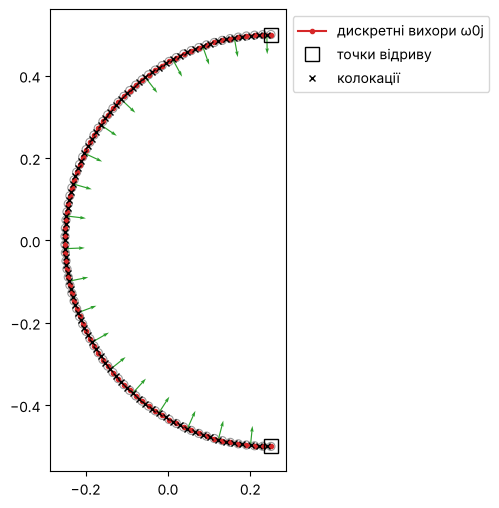

Γ0 = -1: ΣΓ = -1.000000000000, max|V·n| = 6.7e-16
Γ0 = +0: ΣΓ = +0.000000000000, max|V·n| = 5.0e-16
Γ0 = +1: ΣΓ = +1.000000000000, max|V·n| = 6.1e-16


In [2]:
c = Contour.semicircle(80)
plot_contour(c, every=4)
plt.show()
for g0 in (-1.0, 0.0, 1.0):
    sol = SteadySolution.solve(c, v_inf=(1, 0), gamma0=g0)
    print(f"Γ0 = {g0:+.0f}: ΣΓ = {sol.G.sum():+.12f}, max|V·n| = {sol.residual():.1e}")

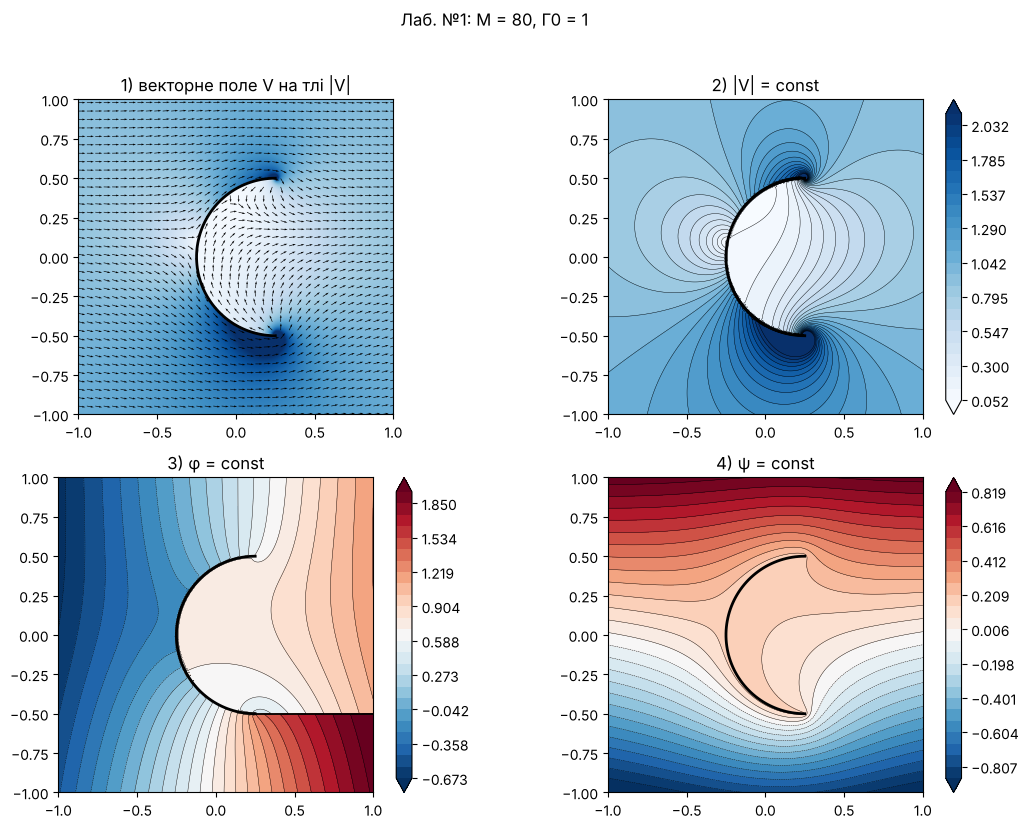

In [3]:
sol = SteadySolution.solve(c, v_inf=(1, 0), gamma0=1.0)
plot_four(sol, xlim=(-1, 1), ylim=(-1, 1), delta=c.h / 2, title="Лаб. №1: M = 80, Γ0 = 1")
plt.show()

## Лаб. №2: відрив вихорів і доріжка Кармана ($\alpha = 0$)

In [4]:
sim = Simulation(Contour.semicircle(24)).run(80, every=1000)
print(sim.summary())

[    21 с] крок 1000: t =  22.16 / 80, вихорів 1434, dt = 0.0210


[    65 с] крок 2000: t =  40.63 / 80, вихорів 1317, dt = 0.0176


[    94 с] крок 3000: t =  58.63 / 80, вихорів 1266, dt = 0.0177


[   125 с] крок 4000: t =  76.73 / 80, вихорів 1262, dt = 0.0180


готово за 131 с: 4180 кроків, t = 80.01, вихорів у сліді 1229
{'Cx_mean': 1.3567247372949127, 'St': 0.24995563052048447}


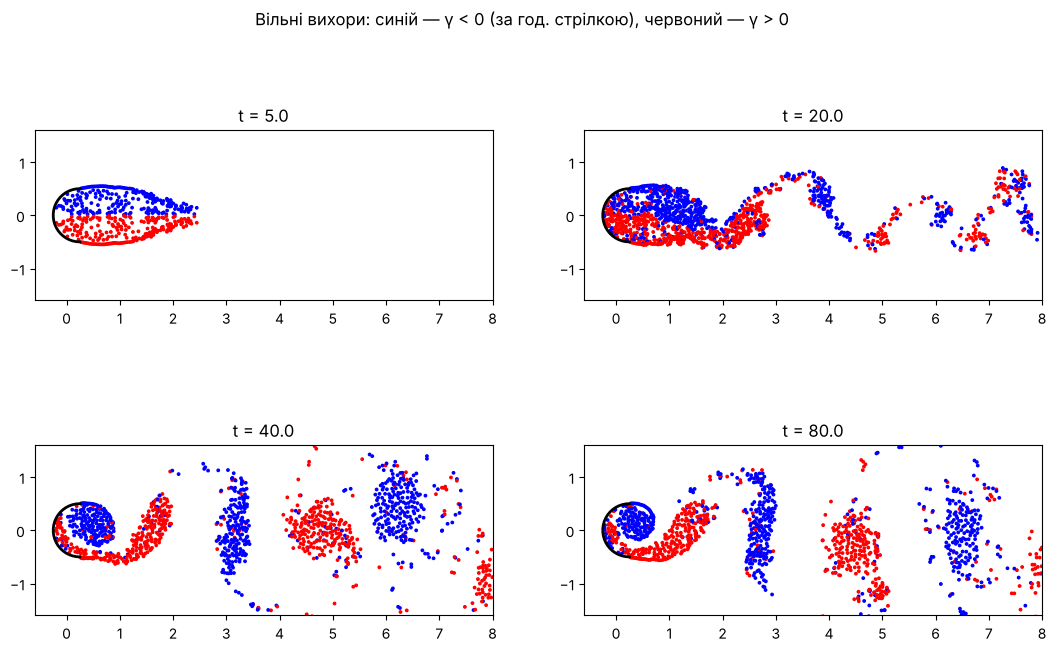

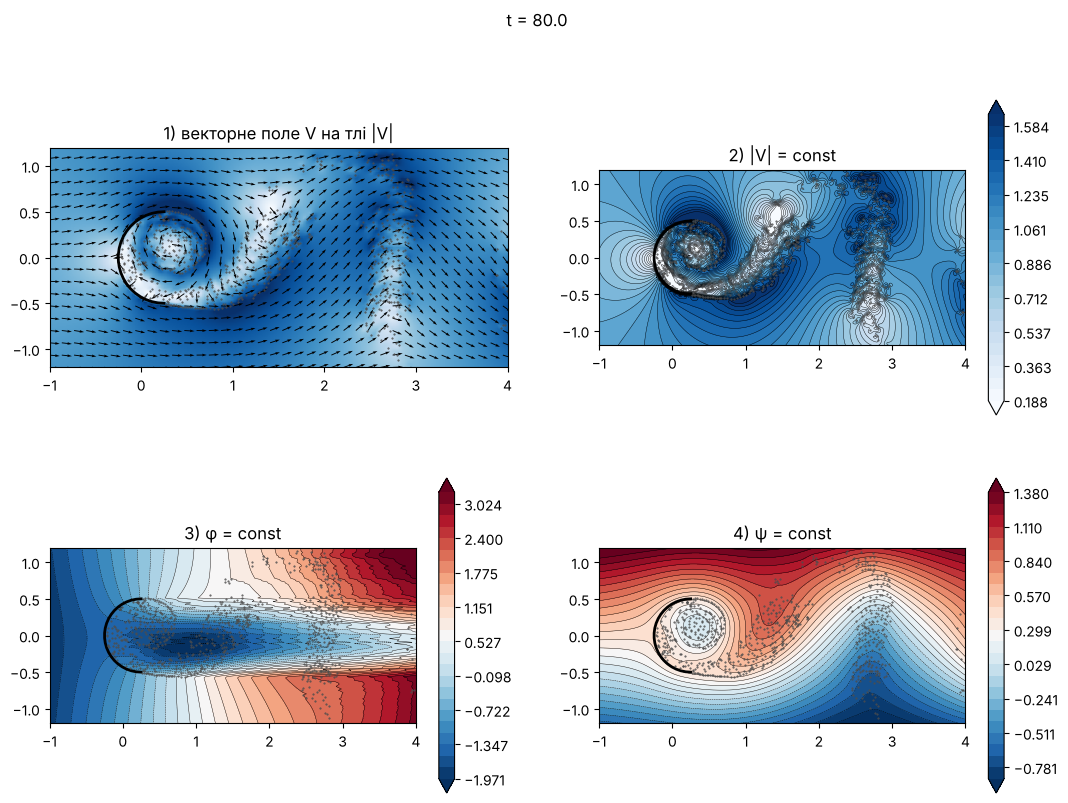

In [5]:
plot_wake(sim, [5, 20, 40, 80])
plt.show()
plot_four(sim, title=f"t = {sim.t:.1f}")
plt.show()

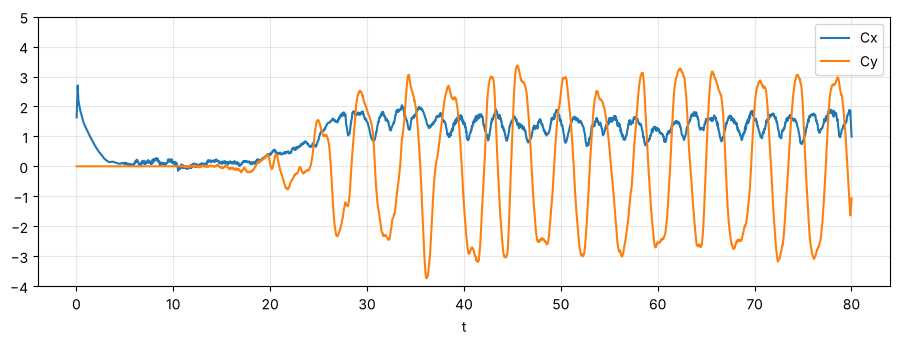

In [6]:
t, Cx, Cy, N = sim.forces()
k = np.ones(15) / 15
plt.figure(figsize=(11, 3.5))
plt.plot(t, np.convolve(Cx, k, 'same'), label='Cx'); plt.plot(t, np.convolve(Cy, k, 'same'), label='Cy')
plt.ylim(-4, 5); plt.legend(); plt.grid(alpha=.3); plt.xlabel('t'); plt.show()

## Будь-яка форма: контур «5» з чотирма точками відриву
Вихори, що залітають у «животик», поглинаються контуром (`absorb`).

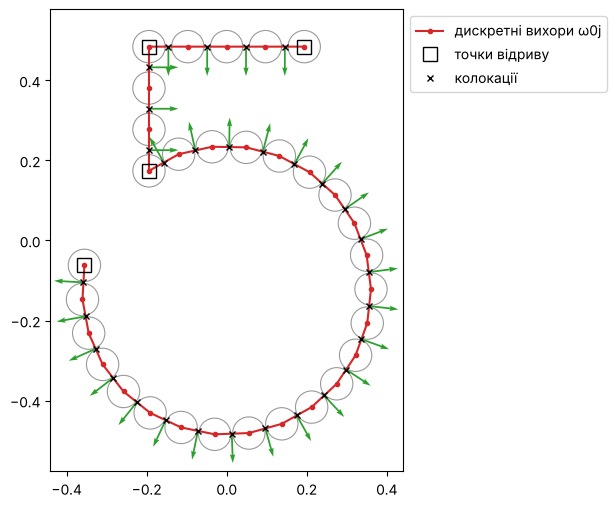

[    14 с] крок 500: t =   8.33 / 20, вихорів 1750, dt = 0.0167


[    64 с] крок 1000: t =  17.03 / 20, вихорів 2073, dt = 0.0164


готово за 87 с: 1176 кроків, t = 20.01, вихорів у сліді 2133


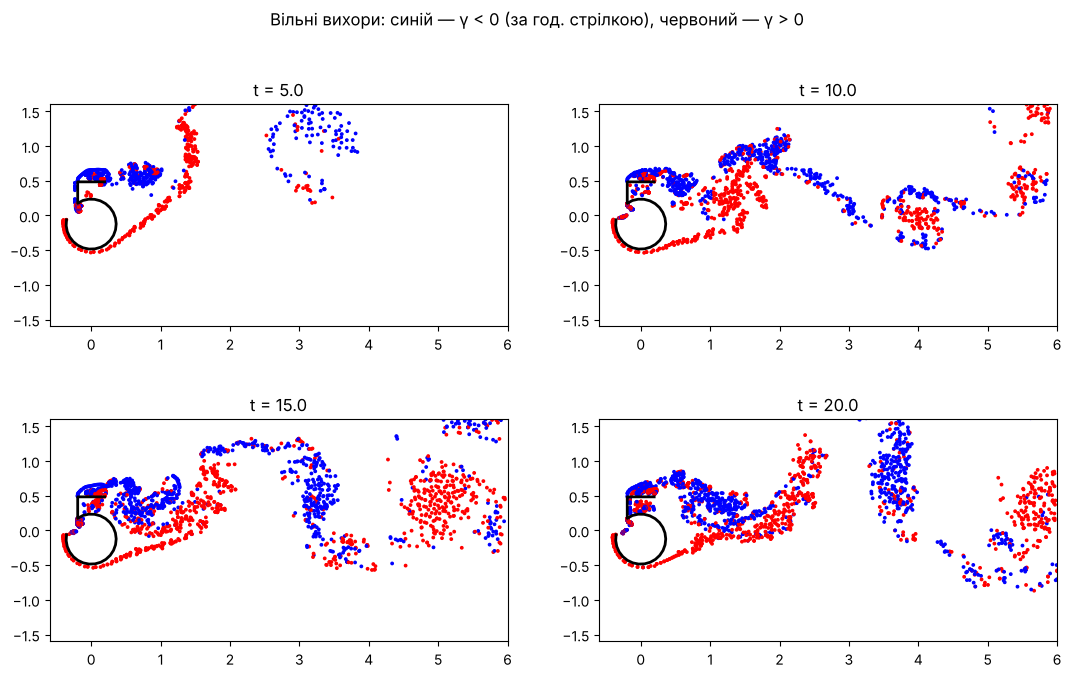

In [7]:
def digit_five(M=31):
    A, B, C = np.array([0.5, 1.25]), np.array([-0.5, 1.25]), np.array([-0.5, 0.45])
    OC, RC = np.array([0.0, -0.32]), 0.93
    a0, a1 = np.arctan2(C[1] - OC[1], C[0] - OC[0]), np.radians(170) - 2 * np.pi
    seg = lambda P, Q, n: P + np.linspace(0, 1, n + 1)[:, None] * (Q - P)
    L = [1.0, 0.8, RC * abs(a1 - a0)]
    n_ab, n_bc = round((M - 1) * L[0] / sum(L)), round((M - 1) * L[1] / sum(L))
    ang = np.linspace(a0, a1, (M - 1) - n_ab - n_bc + 1)
    P = np.vstack([seg(A, B, n_ab), seg(B, C, n_bc)[1:], (OC + RC * np.column_stack([np.cos(ang), np.sin(ang)]))[1:]])
    raw = Contour.from_points(P[:, 0], P[:, 1], separation=[0, n_ab, n_ab + n_bc, M - 1])
    c = raw.normalized()
    shift = np.array([(raw.x0.max() + raw.x0.min()) / 2, (raw.y0.max() + raw.y0.min()) / 2])
    cav = ((OC - shift) / raw.size, RC / raw.size - 3 * c.delta)   # «животик» після нормування
    return c, cav

five, cav = digit_five()
plot_contour(five); plt.show()
sim5 = Simulation(five, x_max=6, absorb=cav).run(20, every=500)
plot_wake(sim5, [5, 10, 15, 20]); plt.show()